# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

%matplotlib inline


In [2]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [5]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

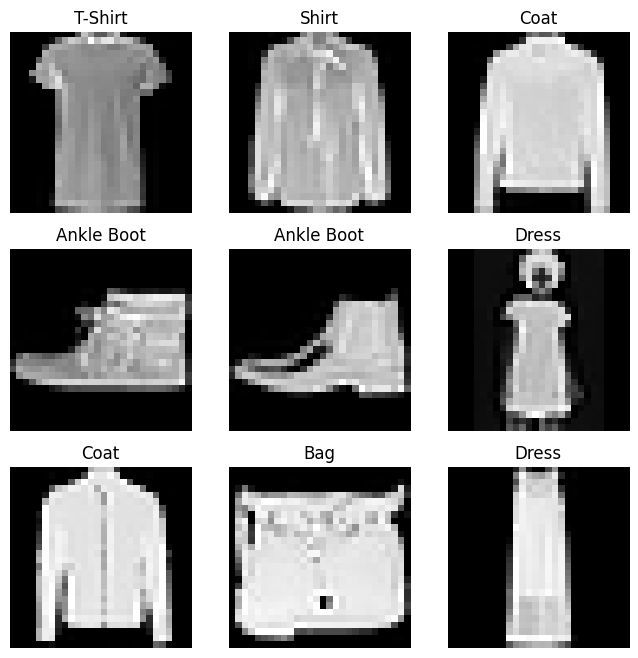

In [6]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [7]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


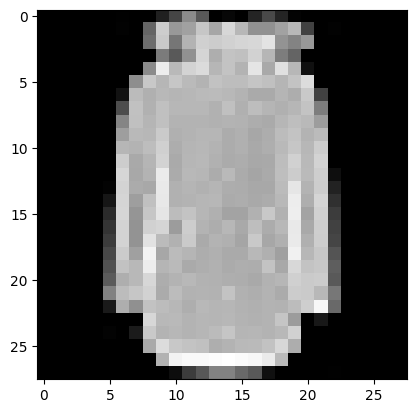

Label: 4


In [8]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [10]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            # your code
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [12]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss, n_batches = 0.0, 0
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        value = loss.item()
        total_loss += value
        n_batches += 1
        if batch_idx % 100 == 0:
            current = (batch_idx + 1) * len(inputs)
            print(f"loss: {value:>7f}  [{current:>5d}/{size:>5d}]")

    mean_loss = total_loss / n_batches
    # Минимум по эпохам нужен, чтобы сравнивать архитектуры не по последнему шагу, а по лучшему.
    if mean_loss < getattr(train, "best_loss", float("inf")):
        train.best_loss = mean_loss
    return mean_loss


In [13]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0.0, 0.0
    num_classes = 10
    confusion = torch.zeros(num_classes, num_classes)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            loss = loss_fn(preds, targets)
            test_loss += loss.item()
            pred_cls = preds.argmax(1)
            num_correct += (pred_cls == targets).sum().item()
            flat = (targets.view(-1) * num_classes + pred_cls.view(-1)).detach().cpu()
            confusion += torch.bincount(flat, minlength=num_classes ** 2).reshape(num_classes, num_classes).float()
    test_loss /= num_batches
    accuracy = num_correct / size
    true_positive = confusion.diag()
    predicted = confusion.sum(0)
    actual = confusion.sum(1)
    precision = torch.where(predicted > 0, true_positive / predicted, torch.zeros_like(true_positive)).mean().item()
    recall = torch.where(actual > 0, true_positive / actual, torch.zeros_like(true_positive)).mean().item()
    print(
        f"Test Error: \n Accuracy: {(100 * accuracy):>0.1f}%, Avg loss: {test_loss:>8f}, "
        f"Precision macro: {precision:.3f}, Recall macro: {recall:.3f} \n"
    )
    if test_loss < getattr(test, "best_loss", float("inf")):
        test.best_loss = test_loss
        print(f"новый минимум test loss: {test.best_loss:.4f}")
    return {"loss": test_loss, "accuracy": accuracy, "precision": precision, "recall": recall}


Задание: Добавьте метрики precision и recall для проверки

**Ответ.** Считаются в `test`: по накопленной матрице ошибок macro-precision и macro-recall, без усреднения по классам, которых нет в батчах. Для FashionMNIST все 10 классов представлены, так что macro — это просто среднее по классам. Accuracy одна на все примеры, precision/recall показывают, не проседает ли какой-то класс.


In [14]:
import copy

def run_experiment(model, optimizer, epochs=10, title="model"):
    if hasattr(test, "best_loss"):
        del test.best_loss
    if hasattr(train, "best_loss"):
        del train.best_loss
    history = []
    best_loss = float("inf")
    best_state = None
    for epoch in range(epochs):
        print(f"Epoch {epoch + 1} ({title})\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        metrics = test(test_dataloader, model, loss_fn)
        history.append({"train_loss": train_loss, **metrics})
        if metrics["loss"] < best_loss:
            best_loss = metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
    best_acc = max(row["accuracy"] for row in history)
    print(f"{title}: минимум test loss {best_loss:.4f}, лучшая accuracy {best_acc:.3f}")
    return history, best_state


torch.manual_seed(0)
model = NeuralNetwork().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
history_view, state_view = run_experiment(model, optimizer, epochs=10, title="view + Linear")
torch.save(state_view, "simple_cnn_view.pth")


Epoch 1 (view + Linear)
-------------------------------
loss: 2.284773  [   64/60000]
loss: 0.809019  [ 6464/60000]
loss: 0.614011  [12864/60000]
loss: 0.670509  [19264/60000]
loss: 0.542343  [25664/60000]
loss: 0.444301  [32064/60000]
loss: 0.413398  [38464/60000]
loss: 0.558780  [44864/60000]
loss: 0.323185  [51264/60000]
loss: 0.573708  [57664/60000]
Test Error: 
 Accuracy: 84.6%, Avg loss: 0.442742, Precision macro: 0.846, Recall macro: 0.846 

новый минимум test loss: 0.4427
Epoch 2 (view + Linear)
-------------------------------
loss: 0.522408  [   64/60000]
loss: 0.373815  [ 6464/60000]
loss: 0.357430  [12864/60000]
loss: 0.323756  [19264/60000]
loss: 0.333125  [25664/60000]
loss: 0.418889  [32064/60000]
loss: 0.468253  [38464/60000]
loss: 0.337853  [44864/60000]
loss: 0.245508  [51264/60000]
loss: 0.181539  [57664/60000]
Test Error: 
 Accuracy: 86.2%, Avg loss: 0.390288, Precision macro: 0.862, Recall macro: 0.862 

новый минимум test loss: 0.3903
Epoch 3 (view + Linear)
------

Осталось сохранить модель для дальнейшего использования.

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

## Пулинг вместо view

Глобальный `AvgPool2d` / `MaxPool2d` с ядром во весь вход (здесь карта 16×28×28, ядро 28) сжимает каждую карту до одного числа. Голова становится `Linear(16, 10)`. Пространственная раскладка при этом выбрасывается: голове остаётся только «насколько канал активировался в среднем или в максимуме». Оптимизатор и число эпох те же, что у модели с `view`, иначе сравнение смешает архитектуру и обучение.


In [15]:
class NeuralNetworkPool(nn.Module):
    def __init__(self, pool):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
        )
        self.pool = pool
        self.head = nn.Linear(16, 10)

    def forward(self, x):
        x = self.base(x)
        x = self.pool(x)
        # пулинг оставляет размерность 1x1, её всё равно нужно убрать
        x = x.view(x.size(0), -1)
        return self.head(x)


histories = {"view + Linear": history_view}
states = {"view + Linear": state_view}

for pool_name, pool in [
    ("AvgPool 28", nn.AvgPool2d(kernel_size=28)),
    ("MaxPool 28", nn.MaxPool2d(kernel_size=28)),
]:
    torch.manual_seed(0)
    pooled = NeuralNetworkPool(pool).to(device)
    opt = torch.optim.SGD(pooled.parameters(), lr=1e-3)
    history, state = run_experiment(pooled, opt, epochs=10, title=pool_name)
    histories[pool_name] = history
    states[pool_name] = state


Epoch 1 (AvgPool 28)
-------------------------------
loss: 2.371435  [   64/60000]
loss: 2.296837  [ 6464/60000]
loss: 2.294497  [12864/60000]
loss: 2.278128  [19264/60000]
loss: 2.261389  [25664/60000]
loss: 2.262908  [32064/60000]
loss: 2.261829  [38464/60000]
loss: 2.280596  [44864/60000]
loss: 2.241781  [51264/60000]
loss: 2.214564  [57664/60000]
Test Error: 
 Accuracy: 21.0%, Avg loss: 2.226568, Precision macro: 0.138, Recall macro: 0.210 

новый минимум test loss: 2.2266
Epoch 2 (AvgPool 28)
-------------------------------
loss: 2.211836  [   64/60000]
loss: 2.243684  [ 6464/60000]
loss: 2.217496  [12864/60000]
loss: 2.238705  [19264/60000]
loss: 2.156699  [25664/60000]
loss: 2.220474  [32064/60000]
loss: 2.218438  [38464/60000]
loss: 2.255197  [44864/60000]
loss: 2.191582  [51264/60000]
loss: 2.223833  [57664/60000]
Test Error: 
 Accuracy: 28.0%, Avg loss: 2.187677, Precision macro: 0.253, Recall macro: 0.280 

новый минимум test loss: 2.1877
Epoch 3 (AvgPool 28)
---------------

## Своя модель

Две свёртки без уменьшения разрешения оставляют голове 16×28×28 признаков, а глобальный пулинг выкидывает координаты. Ниже сеть поглубже: блоки 32 и 64 с `MaxPool2d(2)`, затем 128 каналов и `AdaptiveAvgPool2d(1)`. Пространство сжимается постепенно, а не одним срезом в линейный слой. Обучение — Adam с lr `1e-3`, 10 эпох, тот же FashionMNIST.


MyCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, c

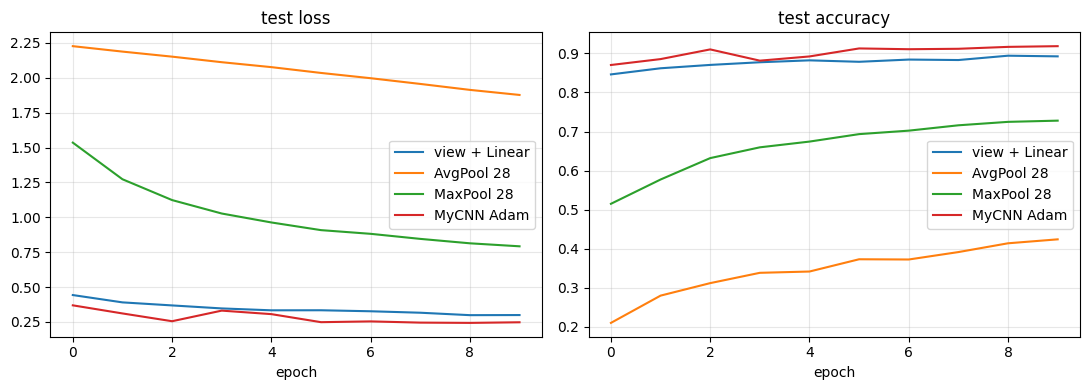

In [16]:
class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.features(x))


torch.manual_seed(0)
custom = MyCNN().to(device)
print(custom)
print("параметров:", sum(p.numel() for p in custom.parameters()))
custom_opt = torch.optim.Adam(custom.parameters(), lr=1e-3)
history_custom, state_custom = run_experiment(custom, custom_opt, epochs=10, title="MyCNN Adam")
histories["MyCNN Adam"] = history_custom
states["MyCNN"] = state_custom
torch.save(state_custom, "simple_cnn_custom.pth")


def best_row(history):
    return max(history, key=lambda row: row["accuracy"])


rows = []
for name, history in histories.items():
    row = best_row(history)
    rows.append({
        "модель": name,
        "лучшая accuracy": round(row["accuracy"], 4),
        "precision macro": round(row["precision"], 3),
        "recall macro": round(row["recall"], 3),
        "test loss на этой эпохе": round(row["loss"], 4),
        "min test loss": round(min(item["loss"] for item in history), 4),
    })
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, history in histories.items():
    axes[0].plot([row["loss"] for row in history], label=name)
    axes[1].plot([row["accuracy"] for row in history], label=name)
axes[0].set_title("test loss")
axes[1].set_title("test accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


## Сравнение

view + Linear, 10 эпох SGD с lr 1e-3: accuracy 89.4%, precision и recall macro 0.894, минимальный test loss 0.299. Голова видит всю карту 16×28×28.

Глобальный AvgPool2d(28) оставляет 16 средних и падает до 42.4% (test loss 1.88): где сработал фильтр, уже не узнать. MaxPool2d(28) на том же месте лучше, 72.8% и loss 0.792: максимум сохраняет факт «детектор сработал», но координату всё равно выбрасывает. Для одежды положение детали важно, поэтому пулинг на весь вход хуже разворачивания карты.

Своя сеть — блоки 32 и 64 с MaxPool2d(2), затем 128 каналов и AdaptiveAvgPool2d(1), Adam с lr 1e-3. 140458 параметров, лучшая accuracy 91.9%, precision/recall macro около 0.92, минимальный test loss 0.243. Веса этой эпохи в simple_cnn_custom.pth, базовая модель — в simple_cnn_view.pth.
